In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from numpy import log
from scipy.stats import ks_2samp, pareto, kstest, linregress, genpareto, expon, kstest, rv_continuous, kstest, ks_2samp
import statsmodels.api as sm
from scipy.optimize import minimize_scalar
from scipy.special import gamma, gammainc, gammaincc, zeta, erf
from Helpers import *
import pickle
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [2]:
df_GVA = pd.read_csv("datasets/GVA.csv")
F_GVA_all = df_GVA["Victims Killed"].values
F_GVA_all = F_GVA_all[F_GVA_all>0]
x_min_GVA = find_xmin(F_GVA_all)
F_GVA_opt = F_GVA_all[F_GVA_all>=x_min_GVA]

df_PNAS = pd.read_csv("datasets/PNAS+.csv")
F_PNAS_all = df_PNAS["Fatalities"].values
x_min_PNAS = find_xmin(F_PNAS_all)
F_PNAS_opt = F_PNAS_all[F_PNAS_all>=x_min_PNAS]

df_WP = pd.read_excel("datasets/WP.xlsx")
F_WP_all = df_WP["Number"].values
x_min_WP = find_xmin(F_WP_all)
F_WP_opt = F_WP_all[F_WP_all>=x_min_WP]

df_stnfrd = pd.read_csv("datasets/Stanford_MSA_Database.csv")
F_stnfrd_all = df_stnfrd["Total Number of Fatalities"].values
F_stnfrd_all = F_stnfrd_all[F_stnfrd_all>0]
x_min_stnfrd = find_xmin(F_stnfrd_all)
F_stnfrd_opt = F_stnfrd_all[F_stnfrd_all>=x_min_stnfrd]

In [3]:
F_all = np.concatenate([F_stnfrd_all[F_stnfrd_all>3], F_PNAS_all])
ave = np.mean(F_all)
std = np.std(F_all)
model = "powerlaw"
params = np.array([4,3])
print(ave, std**2)
print(100*CCDF(30, model, params))
print(100*(0.5-0.5*erf((30-ave)/(std*np.sqrt(2)))))
sample = np.random.normal(ave, std, 10000000)
100*len(sample[sample>30])/len(sample)

7.058011049723757 35.480060132474584
1.435243686486376
0.0058679153263963


0.00558

In [4]:
np.insert(np.array([3]), 0, 4)

array([4, 3])

In [5]:
np.insert(MLE(F_PNAS_opt, "powerlaw", 4)[0], 0, 4)

array([4.        , 2.97215341])

In [6]:
print("GVA", len(df_GVA), len(F_GVA_opt), 100*len(F_GVA_opt)/len(df_GVA))
print("PNAS", len(F_PNAS_all), len(F_PNAS_opt), 100*len(F_PNAS_opt)/len(F_PNAS_all))
print("Stanford", len(df_stnfrd), len(F_stnfrd_opt), 100*len(F_stnfrd_opt)/len(df_stnfrd))
print("WP", len(F_WP_all), len(F_WP_opt), 100*len(F_WP_opt)/len(F_WP_all))

GVA 5525 1274 23.058823529411764
PNAS 212 212 100.0
Stanford 335 113 33.73134328358209
WP 481 481 100.0


In [7]:
print(x_min_GVA)
print(x_min_PNAS)
print(x_min_stnfrd)
print(x_min_WP)

2
4
5
4


In [8]:
models = ["powerlaw", "lognorm", "weibull", "expo"]
Fs = [F_GVA_opt,  F_PNAS_opt,  F_stnfrd_opt, F_WP_opt]

Fs_name = ["F_GVA_opt", "F_PNAS_opt", "F_stnfrd_opt", "F_WP_opt"]
for index, F in enumerate(Fs):
    ic_df = pd.DataFrame(columns = ["Model","pmf", "params", "R", "AIC", "BIC"])
    N = len(F)
    for model in models:
        fit = MLE(F, model, F.min())
        AIC = 2*len(fit[0]) - 2*fit[1]
        BIC = np.log(N)*len(fit[0]) - 2*fit[1]
        ic_df.loc[len(ic_df)] = [model, model, np.round(fit[0], 2), np.round(fit[1]), np.round(AIC), np.round(BIC)] 
    print(Fs_name[index])
    display(ic_df)

F_GVA_opt


,Model,pmf,params,R,AIC,BIC
0,powerlaw,powerlaw,[2.93],-1771.0,3545.0,3550.0
1,lognorm,lognorm,"[-0.72, 1.0]",-1741.0,3487.0,3497.0
2,weibull,weibull,"[0.46, 0.1]",-1745.0,3493.0,3504.0
3,expo,expo,[0.67],-1799.0,3600.0,3605.0


F_PNAS_opt


,Model,pmf,params,R,AIC,BIC
0,powerlaw,powerlaw,[2.97],-447.0,896.0,900.0
1,lognorm,lognorm,"[-6.75, 2.07]",-447.0,898.0,905.0
2,weibull,weibull,"[0.4, 0.1]",-451.0,905.0,912.0
3,expo,expo,[0.29],-475.0,953.0,956.0


F_stnfrd_opt


,Model,pmf,params,R,AIC,BIC
0,powerlaw,powerlaw,[3.16],-250.0,503.0,505.0
1,lognorm,lognorm,"[-3.48, 1.6]",-250.0,504.0,510.0
2,weibull,weibull,"[0.4, 0.1]",-251.0,507.0,512.0
3,expo,expo,[0.27],-261.0,524.0,526.0


F_WP_opt


,Model,pmf,params,R,AIC,BIC
0,powerlaw,powerlaw,[4.42],-661.0,1324.0,1329.0
1,lognorm,lognorm,"[-1.89, 1.0]",-674.0,1352.0,1361.0
2,weibull,weibull,"[0.63, 0.42]",-707.0,1419.0,1427.0
3,expo,expo,[0.57],-756.0,1514.0,1518.0


In [9]:
## Wrong old order
# models = ["powerlaw", "lognorm", "expo", "weibull", "yule-simon"]
# Fs = [ F_GVA_opt,  F_PNAS_opt,  F_WP_opt,  F_stnfrd_opt]

# Fs_name = ["F_PNAS_opt", "F_WP_opt", "F_GVA_opt", "F_stnfrd_opt"]
# for index, F in enumerate(Fs):
#     ic_df = pd.DataFrame(columns = ["Model","pmf", "params", "R", "AIC", "BIC"])
#     N = len(F)
#     for model in models:
#         fit = MLE(F, model, F.min())
#         AIC = 2*len(fit[0]) - 2*fit[1]
#         BIC = np.log(N)*len(fit[0]) - 2*fit[1]
#         ic_df.loc[len(ic_df)] = [model, model, np.round(fit[0], 2), np.round(fit[1],2), np.round(AIC,2), np.round(BIC)] 
#     print(Fs_name[index])
#     display(ic_df)

In [11]:
# ave = np.mean(F)
# std = np.std(F)
# model = "powerlaw"
# params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
# print(ave, std**2)
# print(100*CCDF(30, model, params))
# print(100*(0.5-0.5*erf((30-ave)/(std*np.sqrt(2)))))
# sample = np.random.normal(ave, std, 10000000)
# 100*len(sample[sample>30])/len(sample)

In [13]:
plt.rcParams.update({
    'font.size' : 18,
    "lines.linewidth": 2,
    "mathtext.fontset": "custom",
    "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic",
    "mathtext.bf": "Arial:bold",
        })

In [23]:
# model = "powerlaw"
# params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
# alphas = []
# for i in range(1000):
#     f_sample = np.random.choice(F, size=N, replace=True)
#     # if f_sample.min()>4: print(i)
#     alphas.append(MLE(f_sample, model, x_min)[0][0])
# alpha_upper = np.max(alphas)
# alpha_lower = np.min(alphas)

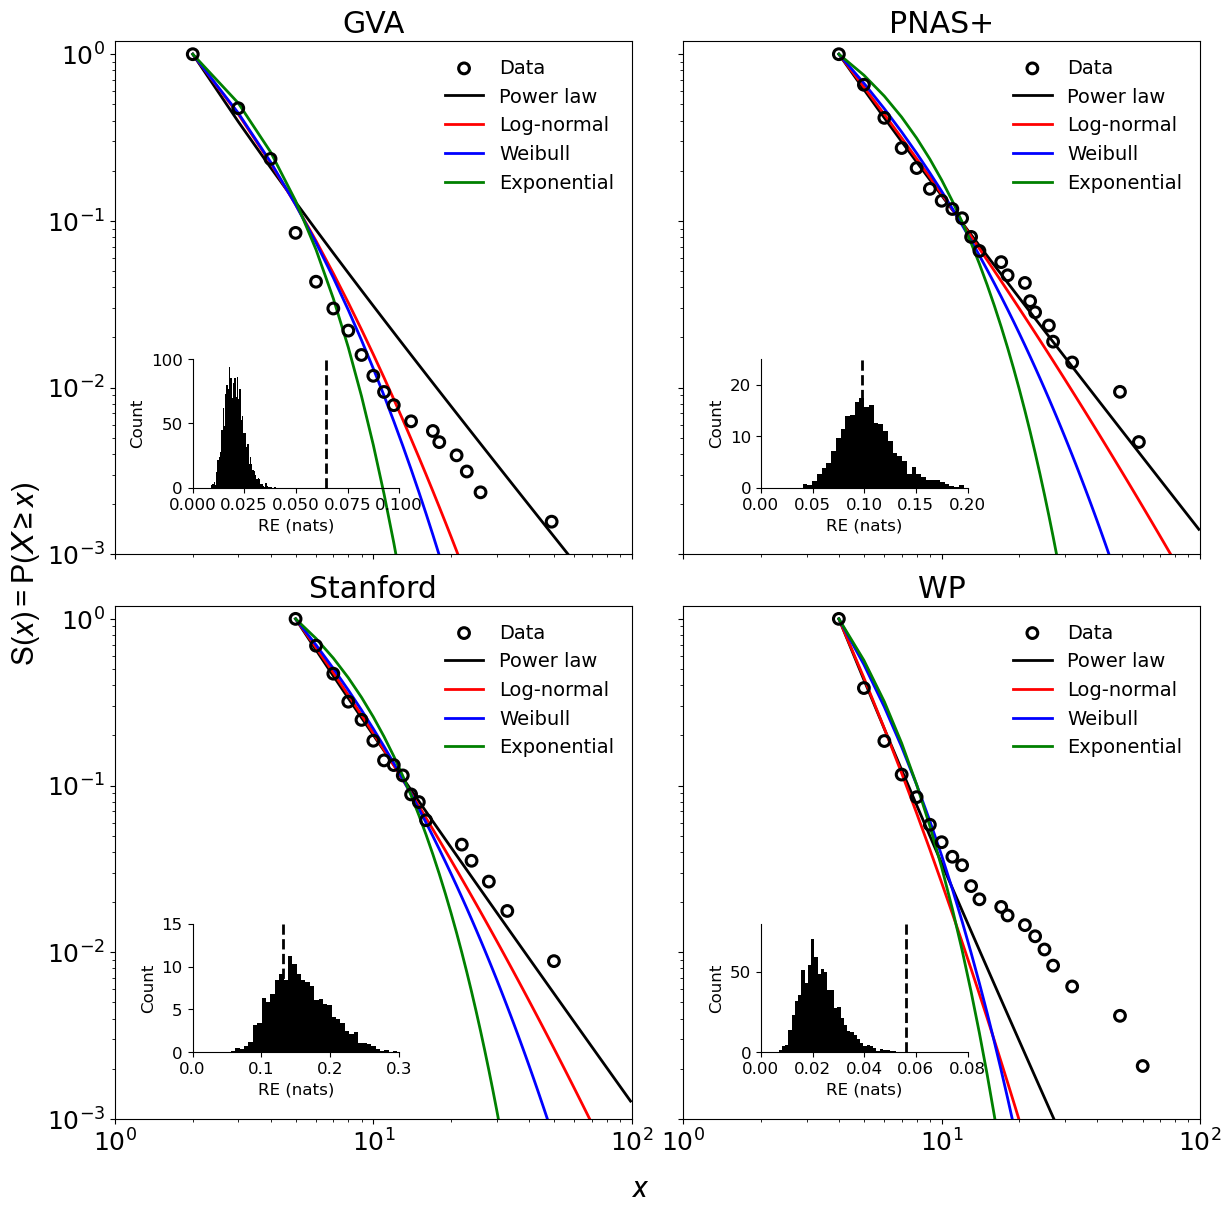

In [33]:
fig, axs = plt.subplots(2, 2, figsize=(14, 14), sharex=True, sharey=True)
axs = axs.flatten()  # easier indexing



fig.supxlabel(r"$\it{x}$", y=0.05)
fig.supylabel(r"$\mathrm{S}(\it{x}) = \mathrm{P}(\it{X} \geq \it{x})$", x=0.05)

fig.subplots_adjust(
    # left=0.08,
    # right=0.98,
    # bottom=0.08,
    # top=0.95,
    wspace=0.1,   # horizontal space between subplots
    hspace=0.1    # vertical space between subplots
)


Fs = [F_GVA_opt, F_PNAS_opt, F_stnfrd_opt, F_WP_opt]
titles = ["GVA", "PNAS+", "Stanford", "WP"]
Surro_names = [
    "Surr_powerlaw_GVA_opt",
    "Surr_powerlaw_PNAS_opt",
    "Surr_powerlaw_stnfrd_opt",
    "Surr_powerlaw_WP_opt",
]

inset_xlim = [
    (0.00, 0.1),   # GVA
    (0.00, 0.2),   # pnas+
    (0.00, 0.3),   # Stanford
    (0.00, 0.08),   # WP
    
]

inset_ylim = [
    (0, 100),
    (0, 25),
    (0, 15),
    (0, 80),
]


for index, F in enumerate(Fs):
    ax = axs[index]
    x_min = F.min()

    # ---- CCDF data ----
    Xs, Sx = plug_in_ccdf(F)
    ax.scatter(
        Xs, Sx,
        facecolors='none',
        edgecolors='k',
        linewidths=2.2,
        s=60,
        label="Data",
        zorder = 5,
    )

    ax.set_xlim([1, 100])
    ax.set_ylim([1e-3, 1.2])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(titles[index])

    # ---- Power-law fit ----
    model = "powerlaw"
    X_fit = np.arange(x_min, 100)
    params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
    fs = CCDF(X_fit, model, params)
    ax.plot(X_fit, fs, color="k", label="Power law")

    model = "lognorm"
    X_fit = np.arange(x_min, 100)
    params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
    fs = CCDF(X_fit, model, params)
    ax.plot(X_fit, fs, color="r", label="Log-normal")

    model = "weibull"
    X_fit = np.arange(x_min, 100)
    params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
    fs = CCDF(X_fit, model, params)
    ax.plot(X_fit, fs, color="b", label="Weibull")

    model = "expo"
    X_fit = np.arange(x_min, 100)
    params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
    fs = CCDF(X_fit, model, params)
    ax.plot(X_fit, fs, color="g", label="Exponential")

    # ---- Power-law fit ----
    model = "powerlaw"
    X_fit = np.arange(x_min, 100)
    params = np.insert(MLE(F, model, x_min)[0], 0, x_min)
    fs = CCDF(X_fit, model, params)

    # ---- Relative entropy ----
    X, Px = plug_in_pdf(F)
    Real_RE = Relative_entropy(X, Px, model, params)

    with open(f"Results/{Surro_names[index]}.pkl", "rb") as f:
        RE = pickle.load(f)

    # ---- Inset histogram ----
    ax_inset = inset_axes(
        ax,
        width="40%",
        height="25%",
        loc="lower left",
        bbox_to_anchor=(0.15, 0.13, 1, 1),
        bbox_transform=ax.transAxes,
        borderpad=0,
    )
    ax_inset.set_facecolor("none")
    ax_inset.hist(RE, bins=50, density=True, color="k")
    ax_inset.axvline(Real_RE, color="k", lw=2, linestyle="--")

    # 🔹 Custom limits per subplot
    ax_inset.set_xlim(inset_xlim[index])
    ax_inset.set_ylim(inset_ylim[index])

    # ---- Clean inset styling ----
    ax_inset.spines["top"].set_visible(False)
    ax_inset.spines["right"].set_visible(False)

    ax_inset.set_xlabel("RE (nats)", fontsize=12)
    ax_inset.set_ylabel("Count", fontsize=12)
    ax_inset.tick_params(labelsize=12)

    ax.legend(frameon=False, loc="upper right", fontsize=14)
plt.savefig("Figure.pdf", bbox_inches="tight")